# SI 671 — Forecasting Model Diagnostics (Validation Only)

**Purpose:** Diagnose two unresolved questions from the completed `05_forecasting_revised.ipynb`:

1. **Poisson temporal-feature ablation:** Do short-term dynamics, variability, and calendar/cyclic additions improve hourly pickup forecasting when the objective is fixed to Poisson?
2. **Boosting convergence:** Are 3,000 boosting rounds a limiting cap? Compare a 3,000-round fit against a 6,000-round fit using the **same features and objective**.

**Method:** Same cleaned 2025 NYC Yellow Taxi inputs, 263 zones, original DST policy, canonical historical OD network merge, and chronological Train (Jan–Aug) / Validation (Sep–Oct). **No Test targets/predictions are used.** Existing final models/results remain untouched. This is model-development work; it does not create a new independent test set.

**Run:** Place this file in `Urban_Mobility_Mining/notebooks/`, select the `si671-urban` kernel, then **Restart Kernel and Run All**. Default is the complete experiment; set `SMOKE_TEST=True` in Configuration only for a fast code check (not reportable).

## 0 — Paths, environment, diagnostic settings

In [1]:
from pathlib import Path
import json, platform, sys, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "data" / "processed" / "cleaned_trips").is_dir(), (
    f"Open the notebook from repository root or notebooks/: {PROJECT_ROOT}"
)
CLEAN_DIR = PROJECT_ROOT / "data/processed/cleaned_trips"
ZONE_FILE = PROJECT_ROOT / "data/external/taxi_zone_lookup.csv"
AUG_FILE = PROJECT_ROOT / "data/processed/network_features/historical_network_features_24h_augmented.parquet"
ORIGINAL_FILE = PROJECT_ROOT / "data/processed/network_features/historical_network_features_24h.parquet"
OUT = PROJECT_ROOT / "results/forecasting/model_diagnostics"
OUT.mkdir(parents=True, exist_ok=True)
SMOKE_TEST = False  # True: quick run only; do NOT interpret/reproduce final statistics
BASE_ROUNDS = 150 if SMOKE_TEST else 3000
EXTENDED_ROUNDS = 250 if SMOKE_TEST else 6000
EARLY_STOPPING_ROUNDS = 30 if SMOKE_TEST else 200
NUM_THREADS = 4  # lower this if your Mac runs out of RAM
RANDOM_SEED = 671
TRAIN_END = pd.Timestamp("2025-09-01")
VAL_END = pd.Timestamp("2025-11-01")
START, END = pd.Timestamp("2025-01-01"), pd.Timestamp("2026-01-01")
TARGET = "pickup_count"
for path in [ZONE_FILE, AUG_FILE]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing required input: {path}")
monthly_paths = [CLEAN_DIR / f"cleaned_2025-{m:02d}.parquet" for m in range(1,13)]
assert all(p.is_file() for p in monthly_paths), "All 12 cleaned_2025-MM.parquet files are required"
print("Root:", PROJECT_ROOT)
print("Kernel:", sys.executable)
print("Python/pandas/LightGBM:", platform.python_version(), pd.__version__, lgb.__version__)
print("Run type:", "SMOKE TEST (not final)" if SMOKE_TEST else "FULL VALIDATION DIAGNOSTICS")
print("Output folder:", OUT)
print("Boosting caps:", BASE_ROUNDS, EXTENDED_ROUNDS)

Root: /Users/wushixundelaopo/Desktop/Urban_Mobility_Mining
Kernel: /opt/anaconda3/envs/si671-urban/bin/python
Python/pandas/LightGBM: 3.11.18 3.1.0 4.7.0
Run type: FULL VALIDATION DIAGNOSTICS
Output folder: /Users/wushixundelaopo/Desktop/Urban_Mobility_Mining/results/forecasting/model_diagnostics
Boosting caps: 3000 6000


## 1 — Reconstruct exactly the same zone-hour panel, features and DST-excluded modeling sample

The next two cells are copied from your successful revised forecasting notebook. No new feature definitions or DST rules are introduced.

In [2]:
zone_lookup = pd.read_csv(ZONE_FILE)
assert "LocationID" in zone_lookup.columns
forecast_zone_ids = sorted(set(zone_lookup["LocationID"].dropna().astype(int)) - {264, 265})
assert len(forecast_zone_ids) == 263, f"Expected 263 zone IDs; got {len(forecast_zone_ids)}"
monthly_panels, source_report = [], []
for month, path in enumerate(monthly_paths, start=1):
    trips = pd.read_parquet(path, columns=["tpep_pickup_datetime", "PULocationID"])
    raw_rows = len(trips)
    month_start = pd.Timestamp(2025, month, 1)
    month_end = month_start + pd.DateOffset(months=1)
    trips = trips.loc[trips["PULocationID"].isin(forecast_zone_ids)].copy()
    times = pd.to_datetime(trips["tpep_pickup_datetime"])
    out_of_month = int(((times < month_start) | (times >= month_end) | times.isna()).sum())
    if out_of_month:
        raise ValueError(f"{path.name}: {out_of_month:,} pickup timestamps outside month; check cleaning source")
    trips["pickup_hour"] = times.dt.floor("h")
    grouped = trips.groupby(["PULocationID", "pickup_hour"], observed=True).size()
    hours = pd.date_range(month_start, month_end, freq="h", inclusive="left")
    keys = pd.MultiIndex.from_product([forecast_zone_ids, hours], names=["PULocationID", "pickup_hour"])
    panel = grouped.reindex(keys, fill_value=0).rename("pickup_count").reset_index()
    panel = panel.rename(columns={"PULocationID": "zone_id"})
    panel["pickup_count"] = panel["pickup_count"].astype("int32")
    assert panel["pickup_count"].sum() == len(trips)
    assert len(panel) == len(forecast_zone_ids)*len(hours)
    monthly_panels.append(panel)
    source_report.append({"month":month_start.strftime("%Y-%m"), "file_rows":raw_rows,
                          "geographic_pickups":len(trips), "zone_hours":len(panel), "hours":len(hours)})
    del trips, panel, grouped, keys

full_year_panel = (pd.concat(monthly_panels, ignore_index=True)
                   .sort_values(["zone_id", "pickup_hour"]).reset_index(drop=True))
del monthly_panels
expected_hours = len(pd.date_range(START, END, freq="h", inclusive="left"))
assert len(full_year_panel) == len(forecast_zone_ids)*expected_hours
assert full_year_panel[["zone_id", "pickup_hour"]].notna().all().all()
assert not full_year_panel.duplicated(["zone_id", "pickup_hour"]).any()
assert full_year_panel["pickup_count"].ge(0).all()
assert full_year_panel["pickup_count"].sum() == sum(x["geographic_pickups"] for x in source_report)
print(f"2025 panel: {len(full_year_panel):,} zone-hours; {expected_hours:,} nominal wall-clock hours")
print("Zero-demand fraction:", round(full_year_panel[TARGET].eq(0).mean(), 4))
display(pd.DataFrame(source_report))

2025 panel: 2,303,880 zone-hours; 8,760 nominal wall-clock hours
Zero-demand fraction: 0.3858


,month,file_rows,geographic_pickups,zone_hours,hours
0,2025-01,3475204,3465683,195672,744
1,2025-02,3577512,3568877,176736,672
2,2025-03,4145224,4135989,195672,744
3,2025-04,3970546,3961555,189360,720
4,2025-05,4591821,4582134,195672,744
5,2025-06,4322940,4314345,189360,720
6,2025-07,3898956,3890590,195672,744
7,2025-08,3574074,3566467,195672,744
8,2025-09,4251008,4242793,189360,720
9,2025-10,4428686,4420144,195672,744


In [3]:
forecast_df = full_year_panel.copy()  # already zone/time sorted
series = forecast_df.groupby("zone_id", sort=False, observed=True)[TARGET]
for lag in [1, 2, 3, 24, 48, 168]:
    forecast_df[f"lag_{lag}"] = series.shift(lag).astype("float32")
for window in [3, 6, 24, 168]:
    forecast_df[f"rolling_mean_{window}"] = series.transform(
        lambda x: x.shift(1).rolling(window, min_periods=window).mean()
    ).astype("float32")
forecast_df["rolling_std_24"] = series.transform(
    lambda x: x.shift(1).rolling(24, min_periods=24).std()
).astype("float32")
forecast_df["trend_3_vs_24"] = (
    forecast_df["rolling_mean_3"] - forecast_df["rolling_mean_24"]
).astype("float32")
t = forecast_df["pickup_hour"]
forecast_df["hour"] = t.dt.hour.astype("int8")
forecast_df["day_of_week"] = t.dt.dayofweek.astype("int8")
forecast_df["is_weekend"] = (t.dt.dayofweek >= 5).astype("int8")
forecast_df["month"] = t.dt.month.astype("int8")
forecast_df["hour_sin"] = np.sin(2*np.pi*t.dt.hour/24).astype("float32")
forecast_df["hour_cos"] = np.cos(2*np.pi*t.dt.hour/24).astype("float32")

DST_BAD_HOURS = [pd.Timestamp("2025-03-09 02:00:00"), pd.Timestamp("2025-11-02 01:00:00")]
forecast_df["dst_history_affected"] = False
for h in DST_BAD_HOURS:
    forecast_df.loc[forecast_df["pickup_hour"].between(h, h+pd.Timedelta(hours=168)),
                    "dst_history_affected"] = True

ORIGINAL_TEMPORAL = ["lag_1", "lag_24", "lag_168", "rolling_mean_24", "rolling_mean_168",
                     "hour", "day_of_week", "is_weekend", "zone_id"]
ENHANCED_EXTRA = ["lag_2", "lag_3", "lag_48", "rolling_mean_3", "rolling_mean_6",
                  "rolling_std_24", "trend_3_vs_24", "month", "hour_sin", "hour_cos"]
ENHANCED_TEMPORAL = ORIGINAL_TEMPORAL + ENHANCED_EXTRA

# Validate history on representative zones and times, including around DST-adjacent periods.
for zone, dt in [(161, "2025-06-10 15:00"), (43, "2025-09-15 10:00")]:
    hit = forecast_df.loc[(forecast_df.zone_id == zone) &
                          (forecast_df.pickup_hour == pd.Timestamp(dt))].iloc[0]
    past = full_year_panel.loc[(full_year_panel.zone_id == zone) &
                               (full_year_panel.pickup_hour < pd.Timestamp(dt))].sort_values("pickup_hour")
    assert np.isclose(hit["lag_1"], past[TARGET].iloc[-1])
    assert np.isclose(hit["rolling_mean_24"], past[TARGET].iloc[-24:].mean())
    assert np.isclose(hit["rolling_mean_3"], past[TARGET].iloc[-3:].mean())

model_df = forecast_df.loc[~forecast_df["dst_history_affected"]].dropna(
    subset=ENHANCED_TEMPORAL + [TARGET]
).copy().sort_values(["pickup_hour", "zone_id"]).reset_index(drop=True)
assert not model_df.duplicated(["zone_id", "pickup_hour"]).any()
assert not model_df["dst_history_affected"].fillna(True).any()
assert model_df[ENHANCED_TEMPORAL + [TARGET]].notna().all().all()
assert model_df[TARGET].ge(0).all()
print("Modeling rows after historical-coverage and DST exclusion:", f"{len(model_df):,}")
print("DST-affected model rows:", int(model_df.dst_history_affected.sum()))
assert len(model_df) == 2_170_802, "Unexpected count relative to prior 2025 pipeline; investigate before fitting"

/var/folders/ww/5mshxs8524ngyq_y2qdc9t9c0000gn/T/ipykernel_92765/2243468088.py:17: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  forecast_df["day_of_week"] = t.dt.dayofweek.astype("int8")
/var/folders/ww/5mshxs8524ngyq_y2qdc9t9c0000gn/T/ipykernel_92765/2243468088.py:18: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  forecast_df["is_weekend"] = (t.dt.dayofweek >= 5).astype("int8")


Modeling rows after historical-coverage and DST exclusion: 2,170,802
DST-affected model rows: 0


## 2 — Verify canonical augmented network merge, then create Train / Validation only

The network merge is retained for **sample alignment**, not for adding network predictors to this experiment. All candidate models use temporal + zone features only, ensuring the temporal feature effects are interpretable.

In [4]:
STRENGTH = ["in_strength_24h", "out_strength_24h",
            "interzone_in_strength_24h", "interzone_out_strength_24h"]
DEGREE = ["in_degree_24h", "out_degree_24h"]
HHI = ["in_hhi_24h", "out_hhi_24h"]
FLOW_FLAGS = ["has_interzone_in_flow_24h", "has_interzone_out_flow_24h"]
KEY_LEFT, KEY_NET = ["zone_id", "pickup_hour"], ["zone_id", "feature_as_of"]
net = pd.read_parquet(AUG_FILE)
required = set(KEY_NET + STRENGTH + DEGREE + HHI + FLOW_FLAGS +
               ["has_full_history_24h", "dst_safe_24h"])
assert required.issubset(net.columns), f"Missing augmented feature fields: {required - set(net.columns)}"
net["zone_id"] = net["zone_id"].astype("int32")
net["feature_as_of"] = pd.to_datetime(net["feature_as_of"])
assert not net.duplicated(KEY_NET).any()
assert net["zone_id"].nunique() == len(forecast_zone_ids)

model_df["zone_id"] = model_df["zone_id"].astype("int32")
model_df["pickup_hour"] = pd.to_datetime(model_df["pickup_hour"])
merged = model_df.merge(net, how="left", left_on=KEY_LEFT, right_on=KEY_NET,
                        validate="one_to_one", indicator=True)
assert len(merged) == len(model_df)
assert merged["_merge"].eq("both").all(), "Some forecast zone-hours failed to join"
assert merged["pickup_hour"].eq(merged["feature_as_of"]).all()
valid_network = (merged["has_full_history_24h"].fillna(False).astype(bool)
                 & merged["dst_safe_24h"].fillna(False).astype(bool)
                 & ~merged["dst_history_affected"].fillna(True).astype(bool))
canonical_df = merged.loc[valid_network].drop(columns=["_merge"]).copy()
del merged
assert not canonical_df.empty
assert not canonical_df.duplicated(KEY_LEFT).any()
assert canonical_df[STRENGTH + DEGREE].notna().all().all()
for direction in ["in", "out"]:
    miss = canonical_df[f"{direction}_hhi_24h"].isna()
    has_flow = canonical_df[f"has_interzone_{direction}_flow_24h"].astype(bool)
    assert (miss == ~has_flow).all(), f"HHI/flow-availability mismatch: {direction}"
    assert canonical_df.loc[~miss, f"{direction}_hhi_24h"].between(0, 1).all()
    assert canonical_df[f"{direction}_degree_24h"].ge(0).all()

# Compare old strength-only file with augmented table, when provided.
if ORIGINAL_FILE.exists():
    original = pd.read_parquet(ORIGINAL_FILE, columns=KEY_NET + STRENGTH)
    original["feature_as_of"] = pd.to_datetime(original["feature_as_of"])
    a = original.sort_values(KEY_NET).reset_index(drop=True)
    b = net[KEY_NET + STRENGTH].sort_values(KEY_NET).reset_index(drop=True)
    pd.testing.assert_frame_equal(a[KEY_NET], b[KEY_NET], check_dtype=False)
    pd.testing.assert_frame_equal(a[STRENGTH], b[STRENGTH], check_dtype=False)
    del original, a, b
    print("PASS: original and augmented strength tables are key/value identical")
else:
    print("Original strength-only parquet absent: cross-version comparison skipped")

print("Merged common sample:", f"{len(canonical_df):,}", "of", f"{len(model_df):,}")
print("Undefined in/out HHI:", *(f"{canonical_df[x].isna().sum():,}" for x in HHI))

PASS: original and augmented strength tables are key/value identical
Merged common sample: 2,170,802 of 2,170,802
Undefined in/out HHI: 103,738 195,447


In [5]:
# Train / Validation only: test data must not enter model selection
canonical_df = canonical_df.sort_values(["pickup_hour", "zone_id"]).reset_index(drop=True)
train = canonical_df.loc[canonical_df["pickup_hour"] < TRAIN_END].copy()
val = canonical_df.loc[(canonical_df["pickup_hour"] >= TRAIN_END) &
                       (canonical_df["pickup_hour"] < VAL_END)].copy()
assert len(train) == 1_445_185 and len(val) == 385_032, (
    f"Unexpected split sizes: {len(train):,}, {len(val):,}"
)
assert train["pickup_hour"].max() < val["pickup_hour"].min()
assert not train.duplicated(["zone_id", "pickup_hour"]).any()
assert not val.duplicated(["zone_id", "pickup_hour"]).any()
zone_dtype = pd.CategoricalDtype(categories=forecast_zone_ids, ordered=False)
for d in (train, val):
    d["zone_id"] = d["zone_id"].astype(zone_dtype)
    assert d[ENHANCED_TEMPORAL + [TARGET]].notna().all().all()
print(f"Train: {len(train):,} | Validation: {len(val):,}")
print("Training ends:", train.pickup_hour.max(), "| Validation starts:", val.pickup_hour.min())
# Save only a lightweight manifest, never overwrite existing final_rq3/ files.


Train: 1,445,185 | Validation: 385,032
Training ends: 2025-08-31 23:00:00 | Validation starts: 2025-09-01 00:00:00


## 3 — Experiment A: Poisson temporal-feature group ablation

Each candidate uses **exactly the same rows**, Poisson objective, validation L1 metric, learning rate and tree configuration; only the added feature group changes. `Original + all extras` is tested as a reference. The **validation-selected** feature set can be a group, the full set, or the original set.

Feature groups are disjoint:

- **Short-term:** `lag_2`, `lag_3`, `rolling_mean_3`, `rolling_mean_6`, `trend_3_vs_24`
- **Variability:** `lag_48`, `rolling_std_24`
- **Calendar/cyclic:** `month`, `hour_sin`, `hour_cos`

We retain existing `hour` even when adding sine/cosine; this is an **incremental** test, not a replacement of hour encoding. All three groups together reproduce `ENHANCED_TEMPORAL` exactly.

In [6]:
from time import perf_counter
GROUPS = {
    "Short-term dynamics": ["lag_2", "lag_3", "rolling_mean_3", "rolling_mean_6", "trend_3_vs_24"],
    "Historical variability": ["lag_48", "rolling_std_24"],
    "Calendar and cyclic": ["month", "hour_sin", "hour_cos"],
}
assert set(sum(GROUPS.values(), [])) == set(ENHANCED_EXTRA)
assert len(sum(GROUPS.values(), [])) == len(set(sum(GROUPS.values(), [])))
CANDIDATES = {
    "Original": list(ORIGINAL_TEMPORAL),
    **{f"Original + {k}": ORIGINAL_TEMPORAL + v for k, v in GROUPS.items()},
    "Original + all extras": list(ENHANCED_TEMPORAL),
}
assert all(len(cols) == len(set(cols)) for cols in CANDIDATES.values())
print(pd.DataFrame([{"candidate": k, "n_features": len(v),
                    "added_features": ", ".join(x for x in v if x not in ORIGINAL_TEMPORAL)}
                   for k, v in CANDIDATES.items()]).to_string(index=False))

                        candidate  n_features                                                                                                 added_features
                         Original           9                                                                                                               
   Original + Short-term dynamics          14                                                    lag_2, lag_3, rolling_mean_3, rolling_mean_6, trend_3_vs_24
Original + Historical variability          11                                                                                         lag_48, rolling_std_24
   Original + Calendar and cyclic          12                                                                                      month, hour_sin, hour_cos
            Original + all extras          19 lag_2, lag_3, lag_48, rolling_mean_3, rolling_mean_6, rolling_std_24, trend_3_vs_24, month, hour_sin, hour_cos


In [7]:
# One training implementation for *both* experiments; no test set accesses.
COMMON_PARAMS = {
    "objective": "poisson",
    "metric": "l1",  # one metric for early stopping
    "learning_rate": 0.05,
    "num_leaves": 31,
    "min_child_samples": 20,
    "random_state": RANDOM_SEED,
    "n_jobs": NUM_THREADS,
    "verbosity": -1,
}

model_cache = {}
validation_predictions = {}
learning_history = {}
all_rows = []

def run_candidate(label, feature_columns, max_rounds):
    key = (tuple(feature_columns), int(max_rounds))
    if key in model_cache:
        return model_cache[key]

    start = perf_counter()
    estimator = lgb.LGBMRegressor(**COMMON_PARAMS, n_estimators=max_rounds)
    eval_history = {}
    estimator.fit(
        train[feature_columns], train[TARGET],
        eval_set=[(val[feature_columns], val[TARGET])],
        eval_metric="l1",
        categorical_feature=["zone_id"],
        callbacks=[
            lgb.early_stopping(EARLY_STOPPING_ROUNDS, first_metric_only=True, verbose=False),
            lgb.log_evaluation(1000),
            lgb.record_evaluation(eval_history),
        ],
    )
    # Poisson predictions are strictly nonnegative; no clipping is applied.
    y_val = val[TARGET].to_numpy(dtype=np.float64)
    pred = np.asarray(estimator.predict(val[feature_columns], num_iteration=estimator.best_iteration_), dtype=np.float64)
    assert np.isfinite(pred).all() and (pred >= 0).all()
    mae = float(np.abs(y_val - pred).mean())
    rmse = float(np.sqrt(np.mean((y_val - pred) ** 2)))
    best_it = int(estimator.best_iteration_ or max_rounds)
    row = dict(candidate=label, max_rounds=int(max_rounds), n_features=len(feature_columns),
               objective="poisson", best_iteration=best_it, best_at_cap=best_it >= max_rounds-10,
               val_mae=mae, val_rmse=rmse, seconds=round(perf_counter()-start, 1))
    model_cache[key] = row
    learning_history[key] = eval_history
    validation_predictions[key] = pred
    all_rows.append(row)
    print(f"{label:34s} | cap={max_rounds:4d} | best={best_it:4d} | "
          f"MAE={mae:.5f} | RMSE={rmse:.4f} | {row['seconds']:.1f}s")
    return row

for label, features in CANDIDATES.items():
    run_candidate(label, features, BASE_ROUNDS)

group_results_df = pd.DataFrame(all_rows).sort_values(["val_mae", "candidate"]).reset_index(drop=True)
original_mae = next(r["val_mae"] for r in all_rows if r["candidate"] == "Original" and r["max_rounds"] == BASE_ROUNDS)
group_results_df["mae_reduction_vs_original_pct"] = 100 * (original_mae - group_results_df["val_mae"]) / original_mae
print("Experiment A (Validation-only):")
display(group_results_df.round(5))
selected_label = str(group_results_df.iloc[0]["candidate"])
selected_features = CANDIDATES[selected_label]
print("Selected by Validation MAE at base cap:", selected_label)

/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.49048
[2000]	valid_0's l1: 3.41242
[3000]	valid_0's l1: 3.37813
Original                           | cap=3000 | best=3000 | MAE=3.37813 | RMSE=9.5440 | 51.1s


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.48041
[2000]	valid_0's l1: 3.40027
[3000]	valid_0's l1: 3.36534
Original + Short-term dynamics     | cap=3000 | best=3000 | MAE=3.36534 | RMSE=9.5333 | 59.1s


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.48474
[2000]	valid_0's l1: 3.40699
[3000]	valid_0's l1: 3.37248
Original + Historical variability  | cap=3000 | best=2997 | MAE=3.37248 | RMSE=9.5338 | 57.5s


... (2 outputs left out)

/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.54901
[2000]	valid_0's l1: 3.48324
[3000]	valid_0's l1: 3.45819
Original + all extras              | cap=3000 | best=2991 | MAE=3.45805 | RMSE=9.9936 | 69.1s
Experiment A (Validation-only):


,candidate,max_rounds,n_features,objective,best_iteration,best_at_cap,val_mae,val_rmse,seconds,mae_reduction_vs_original_pct
0,Original + Short-term dynamics,3000,14,poisson,3000,True,3.36534,9.53335,59.1,0.37872
1,Original + Historical variability,3000,11,poisson,2997,True,3.37248,9.53376,57.5,0.16739
2,Original,3000,9,poisson,3000,True,3.37813,9.54397,51.1,0.00000
3,Original + all extras,3000,19,poisson,2991,True,3.45805,9.99360,69.1,-2.36577
4,Original + Calendar and cyclic,3000,12,poisson,2987,False,3.49348,10.12811,59.9,-3.41468


Selected by Validation MAE at base cap: Original + Short-term dynamics


## 4 — Experiment B: 3,000 versus 6,000 boosting rounds

To distinguish **feature changes** from **iteration-cap effects**, extend the **Original** feature set to 6,000 rounds. Also extend the best candidate from Experiment A if it differs from Original. Both configurations include the corresponding 3,000-round results from Experiment A.

> Important: When `best_iteration` is near the cap, this suggests the cap *may* be limiting, but it does not prove convergence or improvement beyond it. Look at validation MAE and the learning curves, not just the iteration count. Early-stopping metrics and reported MAE are both un-clipped L1.

In [8]:
# Cap comparison keeps features fixed within each pair.
run_candidate("Original", CANDIDATES["Original"], EXTENDED_ROUNDS)
if selected_label != "Original":
    run_candidate(selected_label, selected_features, EXTENDED_ROUNDS)

convergence_labels = list(dict.fromkeys(["Original", selected_label]))
convergence_df = (pd.DataFrame([r for r in all_rows if r["candidate"] in convergence_labels])
                  .sort_values(["candidate", "max_rounds"]).reset_index(drop=True))
comparison_rows = []
for label in convergence_labels:
    pair = convergence_df.loc[convergence_df["candidate"] == label].set_index("max_rounds")
    b = pair.loc[BASE_ROUNDS]
    e = pair.loc[EXTENDED_ROUNDS]
    comparison_rows.append({
        "candidate": label,
        "base_best_iteration": int(b.best_iteration),
        "extended_best_iteration": int(e.best_iteration),
        "base_val_mae": float(b.val_mae),
        "extended_val_mae": float(e.val_mae),
        "absolute_mae_improvement": float(b.val_mae-e.val_mae),
        "relative_mae_improvement_pct": float(100*(b.val_mae-e.val_mae)/b.val_mae),
        "extended_best_near_cap": bool(e.best_at_cap),
    })
cap_comparison_df = pd.DataFrame(comparison_rows)
print("Experiment B — Paired feature-set iteration-cap comparison:")
display(cap_comparison_df.round(5))

/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.49048
[2000]	valid_0's l1: 3.41242
[3000]	valid_0's l1: 3.37813
[4000]	valid_0's l1: 3.35765
[5000]	valid_0's l1: 3.34541
[6000]	valid_0's l1: 3.33654
Original                           | cap=6000 | best=5992 | MAE=3.33654 | RMSE=9.4478 | 112.2s


/opt/anaconda3/envs/si671-urban/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[1000]	valid_0's l1: 3.48041
[2000]	valid_0's l1: 3.40027
[3000]	valid_0's l1: 3.36534
[4000]	valid_0's l1: 3.34709
[5000]	valid_0's l1: 3.33769
[6000]	valid_0's l1: 3.32979
Original + Short-term dynamics     | cap=6000 | best=5998 | MAE=3.32978 | RMSE=9.4564 | 127.7s
Experiment B — Paired feature-set iteration-cap comparison:


,candidate,base_best_iteration,extended_best_iteration,base_val_mae,extended_val_mae,absolute_mae_improvement,relative_mae_improvement_pct,extended_best_near_cap
0,Original,3000,5992,3.37813,3.33654,0.04159,1.23123,True
1,Original + Short-term dynamics,3000,5998,3.36534,3.32978,0.03556,1.05670,True


## 5 — Diagnostic figures and safe artifacts

All outputs are stored in `results/forecasting/model_diagnostics/`; **no M0–M4 final models are overwritten**. The charts are exploratory validation plots. The notebook does **not** report test metrics or perform a new test evaluation.

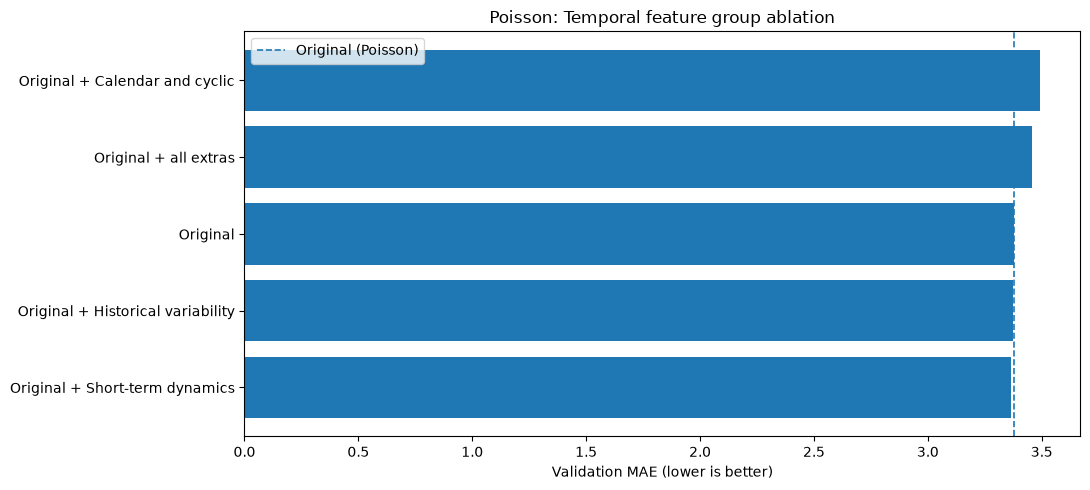

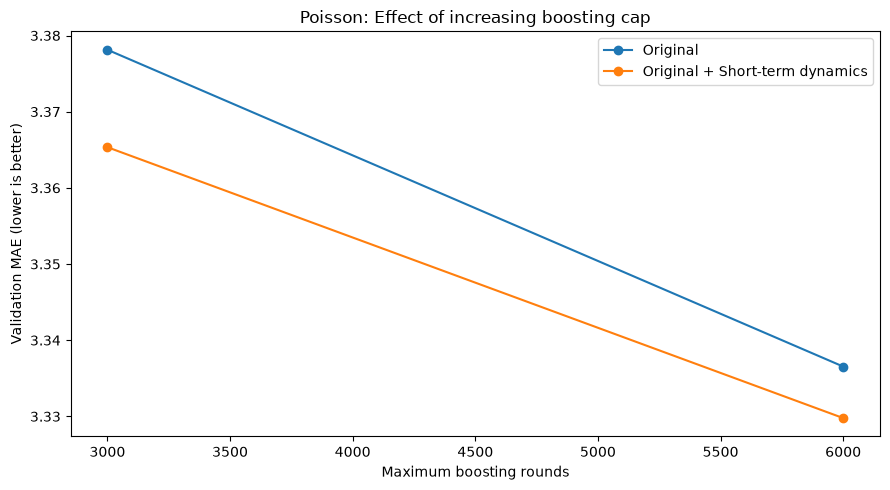

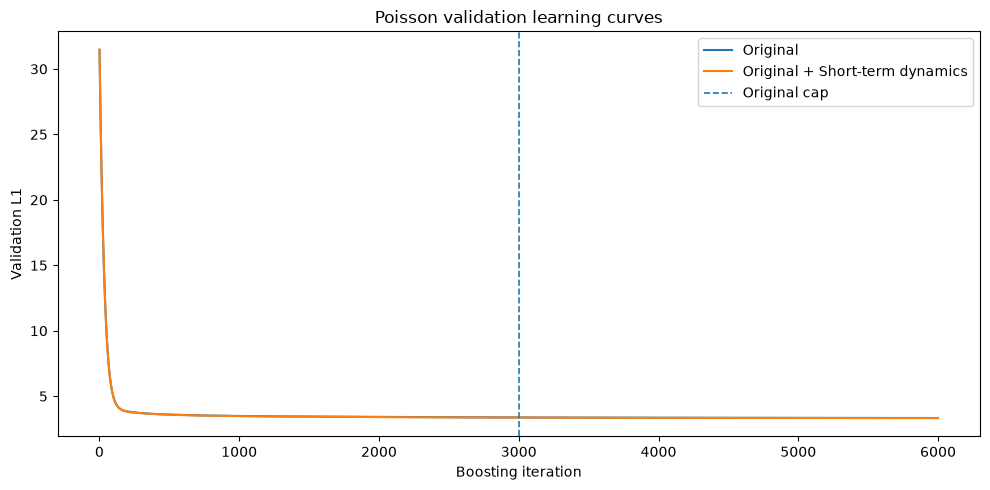

Saved diagnostic reports to: /Users/wushixundelaopo/Desktop/Urban_Mobility_Mining/results/forecasting/model_diagnostics
Reminder: no final_rq3 files were changed and no Test results were accessed.


In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 5))
ordered = group_results_df.sort_values("val_mae", ascending=True)
ax.barh(ordered["candidate"], ordered["val_mae"])
ax.axvline(original_mae, linestyle="--", linewidth=1.2, label="Original (Poisson)")
ax.set(xlabel="Validation MAE (lower is better)", title="Poisson: Temporal feature group ablation")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "poisson_temporal_group_ablation.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for label in convergence_labels:
    d = convergence_df.loc[convergence_df["candidate"] == label].sort_values("max_rounds")
    ax.plot(d["max_rounds"], d["val_mae"], "o-", label=label)
ax.set(xlabel="Maximum boosting rounds", ylabel="Validation MAE (lower is better)",
       title="Poisson: Effect of increasing boosting cap")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "poisson_boosting_cap_comparison.png", dpi=160)
plt.show()

# Plot actual L1 evaluation curves from the extended 6,000-round fits.
fig, ax = plt.subplots(figsize=(10, 5))
for label in convergence_labels:
    key = (tuple(CANDIDATES[label]), int(EXTENDED_ROUNDS))
    history = learning_history[key]
    validation_l1 = history["valid_0"]["l1"]
    ax.plot(np.arange(1, len(validation_l1) + 1), validation_l1, label=label)
ax.axvline(BASE_ROUNDS, linestyle="--", linewidth=1.2, label="Original cap")
ax.set(xlabel="Boosting iteration", ylabel="Validation L1", title="Poisson validation learning curves")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "poisson_validation_learning_curves.png", dpi=160)
plt.show()

group_results_df.to_csv(OUT / "poisson_temporal_group_validation.csv", index=False)
cap_comparison_df.to_csv(OUT / "poisson_iteration_cap_comparison.csv", index=False)
pd.DataFrame(all_rows).to_csv(OUT / "all_validation_candidates.csv", index=False)
manifest = {
    "purpose": "Validation-only temporal-group ablation and boosting convergence diagnostics",
    "train_before": TRAIN_END.isoformat(),
    "validation_start": TRAIN_END.isoformat(),
    "validation_end_exclusive": VAL_END.isoformat(),
    "train_rows": len(train), "validation_rows": len(val),
    "original_features": ORIGINAL_TEMPORAL,
    "feature_groups": GROUPS,
    "selected_at_base_cap": selected_label,
    "common_params": COMMON_PARAMS,
    "base_rounds": BASE_ROUNDS, "extended_rounds": EXTENDED_ROUNDS,
    "smoke_test": SMOKE_TEST,
    "python_version": platform.python_version(), "pandas_version": pd.__version__,
    "lightgbm_version": lgb.__version__,
    "test_data_used": False,
}
with open(OUT / "diagnostics_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)
print("Saved diagnostic reports to:", OUT)
print("Reminder: no final_rq3 files were changed and no Test results were accessed.")

## 6 — Results and Interpretation — Forecasting Model Diagnostics

### Key Findings

This notebook investigates whether temporal feature engineering and additional boosting iterations can improve the forecasting baseline before evaluating further network contributions.

All experiments use Poisson LightGBM and the same chronological training and validation samples.

**Finding 1 — Short-term demand dynamics provide additional predictive information.**

At 3,000 boosting rounds, adding short-term dynamics reduces validation MAE from 3.37813 to 3.36534, an improvement of 0.379%.

The added features capture recent demand levels and changes through short lags, rolling averages, and a short-term trend indicator.

**Finding 2 — More temporal features do not necessarily improve performance.**

Historical variability features provide a smaller improvement of 0.167%. In contrast, calendar/cyclic features and the complete enhanced feature set worsen validation MAE by 3.415% and 2.366%, respectively.

These findings support targeted feature selection rather than automatically including every engineered predictor.

**Finding 3 — Increasing the boosting cap substantially improves validation accuracy.**

Extending training from 3,000 to 6,000 rounds reduces validation MAE:

- Original temporal features: 3.37813 to 3.33654 (1.231% improvement).
- Original + short-term dynamics: 3.36534 to 3.32978 (1.057% improvement).

**Finding 4 — The best temporal configuration combines short-term features with 6,000 boosting rounds.**

The strongest evaluated temporal model achieves:

- Validation MAE: **3.32978**
- Validation RMSE: **9.45644**
- Best iteration: **5,998**

Compared with the original Poisson model at 3,000 rounds, validation MAE decreases by approximately 1.43%.

**Finding 5 — Full boosting convergence has not yet been established.**

Both models trained with a 6,000-round cap reach their best validation iterations near the cap. The results indicate continued improvement, but do not establish an optimal training duration beyond the evaluated range.

### Interpretation

The original forecasting model was limited partly by its boosting iteration cap. Targeted short-term temporal features also improve predictive accuracy, although their contribution is smaller than the improvement associated with additional training rounds.

The results demonstrate that model training configuration and feature selection should be evaluated together, rather than assuming a larger feature set is always beneficial.

### Limitations

These experiments use one chronological validation period and a fixed LightGBM parameter configuration. They do not establish that the selected feature set or boosting cap will generalize equally well to other periods.

Differences in validation MAE may also reflect interactions between feature representations and model capacity.

### Conclusion

The selected enhanced temporal baseline uses Poisson LightGBM, the original temporal features plus short-term dynamics, and a maximum of 6,000 boosting rounds.

This configuration provides a stronger reference model for the subsequent network ablation experiments in Notebook 07.